# Spectral Geometry Refinement (SGR) — Controlled Synthetic Experiment

**Goal.** Determine whether SGR identifies hidden spectral populations within an initially merged cluster **and** avoids subdividing a homogeneous control cluster.

All spectra are synthetic, with known ground-truth labels retained **only for evaluation**. The refinement receives **global labels only**. This is an illustrative benchmark, **not** a reproduction of the dissertation's 16 asteroid groups.

The CPU implementation is used, and the reference GPU spectral-trend intervals are explicitly specified. To shorten execution, `gmm_n_init=2` is used for this demonstration; this is **not** a thesis reference run.

## 1. Generate VIS–NIR spectra with known populations

G1 includes three partly overlapping absorption-band morphologies (position, band depth, and continuum slope), each with 30 spectra. G2 comprises 30 realizations of one profile and serves as a negative-control population. The synthetic populations are intentionally structured, but splitting is determined entirely by SGR's own acceptance criteria.

In [3]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score, silhouette_score

root = Path.cwd()
if not (root / "spectral_geometry_refinement_cpu.py").exists():
    root = root.parent
if not (root / "spectral_geometry_refinement_cpu.py").exists():
    raise FileNotFoundError("Run this notebook inside examples/ or the repository root.")
sys.path.insert(0, str(root))
from spectral_geometry_refinement_cpu import SGRConfig, run_sgr

rng = np.random.default_rng(2026)
wavelengths = np.linspace(0.45, 2.45, 61)
X, global_labels, true_labels = [], [], []

specifications = [(0.90, 1.79, 0.27, 0.035), (1.08, 1.98, 0.31, 0.045), (1.26, 2.14, 0.24, 0.060)]
for population, (c1, c2, strength, slope) in enumerate(specifications):
    for _ in range(30):
        y = 1.0 + (slope + rng.normal(0, 0.003)) * (wavelengths - 0.55)
        y -= (strength + rng.normal(0, 0.008)) * np.exp(-0.5 * ((wavelengths - (c1 + rng.normal(0, 0.006))) / 0.105) ** 2)
        y -= (0.14 + rng.normal(0, 0.005)) * np.exp(-0.5 * ((wavelengths - (c2 + rng.normal(0, 0.008))) / 0.14) ** 2)
        y += rng.normal(0, 0.003, wavelengths.size)
        X.append(y)
        global_labels.append(0)
        true_labels.append(population)

for _ in range(30):
    y = 1.0 + (0.125 + rng.normal(0, 0.002)) * (wavelengths - 0.55)
    y -= (0.20 + rng.normal(0, 0.006)) * np.exp(-0.5 * ((wavelengths - (1.54 + rng.normal(0, 0.005))) / 0.16) ** 2)
    y += rng.normal(0, 0.003, wavelengths.size)
    X.append(y)
    global_labels.append(1)
    true_labels.append(3)

X = np.asarray(X)
global_labels = np.asarray(global_labels)
true_labels = np.asarray(true_labels)
assert X.shape == (120, 61)
print(f"Spectra: {len(X)} | Channels: {X.shape[1]} | Initial clusters: {len(np.unique(global_labels))}")
print("Known synthetic populations:", np.bincount(true_labels))

Spectra: 120 | Channels: 61 | Initial clusters: 2
Known synthetic populations: [30 30 30 30]


## 2. Inspect the generative structure

True labels are used only for visualization and evaluation; they are never passed to `run_sgr`.

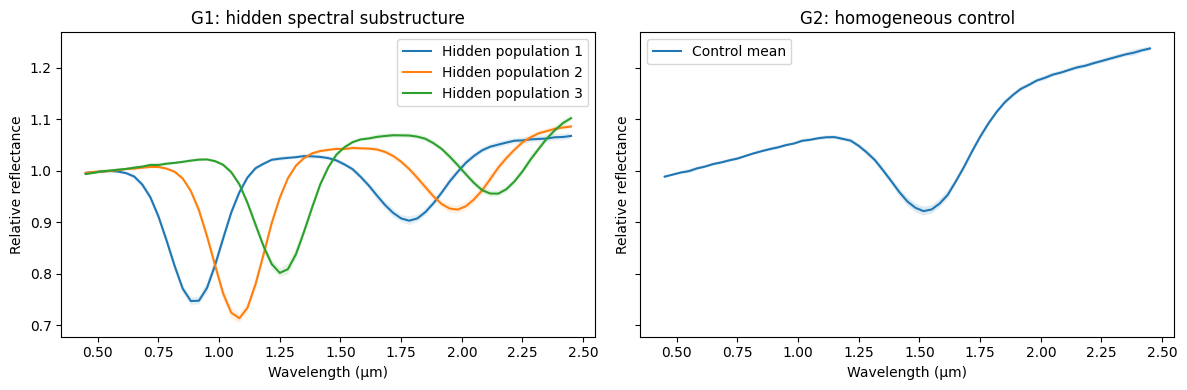

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for group in range(3):
    spectra = X[true_labels == group]
    mean = spectra.mean(axis=0)
    std = spectra.std(axis=0)
    axes[0].plot(wavelengths, mean, label=f"Hidden population {group + 1}")
    axes[0].fill_between(wavelengths, mean - std, mean + std, alpha=0.12)
axes[0].set_title("G1: hidden spectral substructure")
axes[0].legend()
control = X[global_labels == 1]
axes[1].plot(wavelengths, control.mean(axis=0), label="Control mean")
axes[1].fill_between(wavelengths, control.mean(axis=0) - control.std(axis=0), control.mean(axis=0) + control.std(axis=0), alpha=0.15)
axes[1].set_title("G2: homogeneous control")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("Wavelength (µm)")
    ax.set_ylabel("Relative reflectance")
plt.tight_layout()
plt.show()

## 3. Run SGR without ground-truth labels

All acceptance thresholds remain those of the algorithm. The CPU demonstration differs from the thesis GPU run in numerical backend and GMM initialization count. Subdivision outcomes must be observed, not presumed.

In [7]:
cfg = SGRConfig(
    seed=42,
    max_refine_depth=1,
    refine_kmax=4,
    min_parent_n=55,
    min_child_n=3,
    gmm_n_init=2,
    trend_window_channels=(),
    trend_include_full_region=False,
    trend_regions=((0.45, 0.55), (0.55, 2.50), (0.45, 2.50)),
)
result = run_sgr(X, wavelengths, global_labels, config=cfg, make_plots=False)
display(result.history)
print("Subgroup sizes:", np.bincount(result.refined_labels))


===== SPECTRAL GEOMETRY REFINEMENT (SGR) =====
Global clusters : 2
Accepted splits : 1
Refined clusters: 4
G1: K=3 | N=90 | silhouette=0.9634 | agreement=1.0000


,node,global_cluster,depth,N,decision,valid_views,local_K,coherent_landmarks,consensus_silhouette,consensus_ARI
0,G1,0,0,90,SPLIT,9,3,"[R1_B1_positions, R1_B1_shape, R1_B1_core, R1_...",0.96341,1.0
1,G1.1,0,1,30,STOP,0,1,[],NaN,NaN
2,G1.2,0,1,30,STOP,0,1,[],NaN,NaN
3,G1.3,0,1,30,STOP,0,1,[],NaN,NaN
4,G2,1,0,30,STOP,0,1,[],NaN,NaN


Subgroup sizes: [30 30 30 30]


## 4. Quantify recovery against ground truth

**ARI** assesses agreement with the known synthetic populations. **Spectral Silhouette** is computed over the entire reflectance matrix, separately from **consensus Silhouette**, which is used internally by SGR to assess the co-association structure. These are different quantities.

In [9]:
recovered = np.asarray(result.refined_labels)
ari = adjusted_rand_score(true_labels, recovered)
spectral_sil = silhouette_score(X, recovered) if 1 < len(np.unique(recovered)) < len(X) else np.nan
comparison = pd.crosstab(pd.Series(true_labels, name="Known population"), pd.Series(recovered, name="SGR group"))
display(comparison)
print(f"ARI vs synthetic ground truth: {ari:.4f}")
print(f"Silhouette in complete spectral space: {spectral_sil:.4f}")
print(f"Accepted splits: {result.n_splits} | Final groups: {result.n_refined_clusters}")
control_recovered = np.unique(recovered[global_labels == 1])
print(f"Homogeneous control yields {len(control_recovered)} refined group(s)")

SGR group,0,1,2,3
Known population,,,,
0,0,30,0,0
1,0,0,30,0
2,30,0,0,0
3,0,0,0,30


ARI vs synthetic ground truth: 1.0000
Silhouette in complete spectral space: 0.9201
Accepted splits: 1 | Final groups: 4
Homogeneous control yields 1 refined group(s)


## 5. Recovered spectral profiles

Compare recovered mean spectra and observe whether the small clusters, if any, have a distinct morphology. Subdivision can occur without agreement with the known synthetic populations; this is why the ARI and contingency table are included.

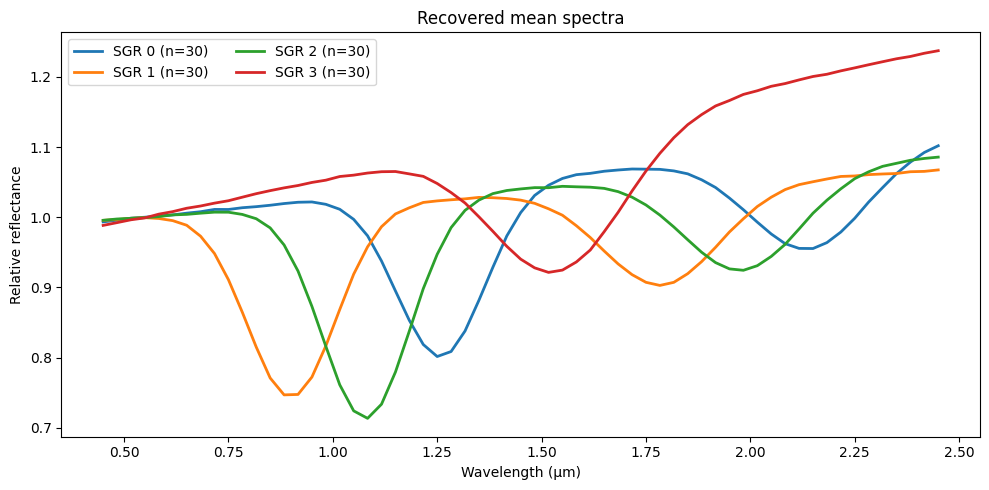

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
for group in np.unique(recovered):
    subset = X[recovered == group]
    ax.plot(wavelengths, subset.mean(axis=0), lw=2, label=f"SGR {group} (n={len(subset)})")
ax.set(xlabel="Wavelength (µm)", ylabel="Relative reflectance", title="Recovered mean spectra")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

## 6. Deterministic stopping-rule check

Set `min_parent_n` above the size of every original group. SGR must preserve the two global clusters. This is a **sanity check for a stopping rule**, not a statistical negative-control experiment.

In [13]:
stopping = run_sgr(X, wavelengths, global_labels, config=SGRConfig(min_parent_n=121), make_plots=False)
assert stopping.n_splits == 0
assert stopping.n_refined_clusters == 2
print("Deterministic stopping-rule check passed.")


===== SPECTRAL GEOMETRY REFINEMENT (SGR) =====
Global clusters : 2
Accepted splits : 0
Refined clusters: 2
Deterministic stopping-rule check passed.


## What this example demonstrates — and what it does not

- A successful refinement shows that SGR's local spectral views, GMM–BIC screening, agreement, and consensus criteria support subdividing a parent cluster.
- The synthetic ARI quantifies recovery against known populations. A high consensus Silhouette alone **does not** imply a high Silhouette in the full spectral space.
- A homogeneous group that is not split provides an informative control; the deterministic stopping-rule check separately validates the minimum-parent-size condition.
- Results here are illustrative and depend on data generation, backend, and initialization. They do **not** validate the 16 asteroid groups or establish CPU/GPU numerical equivalence.